# NBA MVP Prediction Using Machine Learning

This notebook compares four classifiers and a simple baseline, evaluates on later completed seasons, and ranks candidates **within each season**.


**Interpretation note:** this is a historical, end-of-season MVP classification/ranking exercise. The input features are season-end statistics, so this is not a pre-season prediction.

In [1]:
from pathlib import Path
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
TRAIN_END_SEASON = 2021
TEST_START_SEASON = 2022
TEST_END_SEASON = 2025  # Latest season with MVP award labels in the supplied files

def normalize_name(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

def locate_csv(expected_stem):
    # Search common Colab and notebook working directories.
    roots = [Path("/content"), Path.cwd()]
    seen = set()
    for root in roots:
        if not root.exists():
            continue
        for path in root.rglob("*.csv"):
            if str(path) in seen:
                continue
            seen.add(str(path))
            if normalize_name(path.stem) == normalize_name(expected_stem):
                return path
    return None

players_path = locate_csv("Player Per Game")
awards_path = locate_csv("Player Award Shares")

if players_path is None or awards_path is None:
    try:
        from google.colab import files
        print("Could not locate both source CSVs. Upload Player Per Game.csv and Player Award Shares.csv.")
        files.upload()
        players_path = locate_csv("Player Per Game")
        awards_path = locate_csv("Player Award Shares")
    except ImportError:
        pass

if players_path is None or awards_path is None:
    raise FileNotFoundError(
        "Could not find the two source CSVs. Put 'Player Per Game.csv' and "
        "'Player Award Shares.csv' in the notebook folder or upload them in Colab."
    )

print("Player statistics file:", players_path.name)
print("Award shares file:", awards_path.name)

players = pd.read_csv(players_path)
awards = pd.read_csv(awards_path)

print("\nPlayer statistics shape:", players.shape)
print("Award data shape:", awards.shape)
print("Available award types:", sorted(awards["award"].dropna().astype(str).unique()))

Player statistics file: Player Per Game.csv
Award shares file: Player Award Shares.csv

Player statistics shape: (33339, 32)
Award data shape: (3465, 10)
Available award types: ['aba mvp', 'aba roy', 'baa roy', 'nba clutch_poy', 'nba dpoy', 'nba mip', 'nba mvp', 'nba roy', 'nba smoy']


In [2]:
# 1. Clean the player statistics and construct MVP labels.

required_player_columns = {"season", "player", "player_id", "team"}
required_award_columns = {"season", "award", "player", "player_id", "winner"}
if not required_player_columns.issubset(players.columns):
    raise ValueError(f"Player CSV is missing columns: {required_player_columns - set(players.columns)}")
if not required_award_columns.issubset(awards.columns):
    raise ValueError(f"Award CSV is missing columns: {required_award_columns - set(awards.columns)}")

players["season"] = pd.to_numeric(players["season"], errors="coerce")
awards["season"] = pd.to_numeric(awards["season"], errors="coerce")

# When a player played for multiple teams, prefer the combined season row
# (e.g., 2TM) over separate team rows. If no aggregate row exists, keep one row.
players = players.dropna(subset=["season", "player_id"]).copy()
players["_aggregate_row"] = players["team"].astype(str).eq("2TM").astype(int)
players_clean = (
    players.sort_values("_aggregate_row", ascending=False)
    .drop_duplicates(subset=["season", "player_id"], keep="first")
    .drop(columns="_aggregate_row")
    .copy()
)

mvp_awards = awards[
    awards["award"].astype(str).str.strip().str.lower().eq("nba mvp")
].copy()

winner_mask = mvp_awards["winner"].astype(str).str.strip().str.lower().isin(
    ["true", "1", "yes", "y"]
)
mvp_winners = mvp_awards.loc[winner_mask, ["season", "player_id", "player"]].copy()
mvp_winners["MVP"] = 1
mvp_winners = mvp_winners.drop_duplicates(subset=["season", "player_id"])

if mvp_winners.empty:
    raise ValueError("No NBA MVP winners found. Check the 'award' and 'winner' columns.")

# Only use seasons for which the supplied awards file has NBA MVP voting records.
labelled_seasons = sorted(mvp_awards["season"].dropna().astype(int).unique())
players_clean["season"] = players_clean["season"].astype(int)
mvp_winners["season"] = mvp_winners["season"].astype(int)

dataset = players_clean[players_clean["season"].isin(labelled_seasons)].merge(
    mvp_winners[["season", "player_id", "MVP"]],
    on=["season", "player_id"],
    how="left",
    validate="one_to_one"
)
dataset["MVP"] = dataset["MVP"].fillna(0).astype(int)

print("Player rows before duplicate cleanup:", len(players))
print("Player rows after duplicate cleanup:", len(players_clean))
print("Duplicate season/player_id keys after cleanup:",
      dataset.duplicated(subset=["season", "player_id"]).sum())
print("Labelled seasons:", min(labelled_seasons), "to", max(labelled_seasons),
      f"({len(labelled_seasons)} seasons)")
print("Dataset shape:", dataset.shape)
print("Positive MVP labels:", int(dataset["MVP"].sum()))

# Confirm that every winner in the awards file maps to a player statistics row.
stats_keys = set(zip(dataset["season"], dataset["player_id"]))
missing_winners = mvp_winners[
    ~mvp_winners.apply(lambda r: (r["season"], r["player_id"]) in stats_keys, axis=1)
]
print("Award winners absent from player statistics:", len(missing_winners))
if len(missing_winners):
    print(missing_winners[["season", "player", "player_id"]].to_string(index=False))

# Verify a recent known winner from the supplied labels, when present.
recent_season = max(labelled_seasons)
print(f"\nMVP winner(s) in latest labelled season ({recent_season}):")
print(
    dataset.loc[dataset["season"].eq(recent_season) & dataset["MVP"].eq(1),
                 ["season", "player", "player_id", "MVP"]]
    .to_string(index=False)
)

Player rows before duplicate cleanup: 33339
Player rows after duplicate cleanup: 26969
Duplicate season/player_id keys after cleanup: 0
Labelled seasons: 1956 to 2025 (70 seasons)
Dataset shape: (25140, 33)
Positive MVP labels: 70
Award winners absent from player statistics: 0

MVP winner(s) in latest labelled season (2025):
 season                  player player_id  MVP
   2025 Shai Gilgeous-Alexander gilgesh01    1


In [3]:
# 2. Select features and split by season.
# Metadata stays in model_data; only numeric features are passed to estimators.

features = [
    "age", "g", "gs", "mp_per_game", "fg_percent", "x3p_percent",
    "ft_percent", "trb_per_game", "ast_per_game", "stl_per_game",
    "blk_per_game", "tov_per_game", "pts_per_game"
]
target = "MVP"
metadata_cols = ["season", "player", "player_id"]

missing_columns = [col for col in features if col not in dataset.columns]
if missing_columns:
    raise ValueError(f"Feature columns missing from player data: {missing_columns}")

model_data = dataset[metadata_cols + features + [target]].copy()
for col in features:
    model_data[col] = pd.to_numeric(model_data[col], errors="coerce")

# Hold out completed seasons 2022–2025. Do not use 2026 because the supplied
# award file does not contain an NBA MVP label for that season.
train_data = model_data[model_data["season"] <= TRAIN_END_SEASON].copy()
test_data = model_data[
    model_data["season"].between(TEST_START_SEASON, TEST_END_SEASON)
].copy()

if train_data.empty or test_data.empty:
    raise ValueError("Train/test split is empty. Check the season values and split settings.")
if train_data["MVP"].nunique() < 2:
    raise ValueError("Training data must contain both MVP winners and non-winners.")
if test_data["MVP"].nunique() < 2:
    raise ValueError("Test data must contain both MVP winners and non-winners.")

X_train = train_data[features]
y_train = train_data[target].astype(int)
X_test = test_data[features]
y_test = test_data[target].astype(int)

print("Training seasons:", int(train_data["season"].min()), "to", int(train_data["season"].max()))
print("Testing seasons:", int(test_data["season"].min()), "to", int(test_data["season"].max()))
print("Training records:", len(train_data), "| MVP winners:", int(y_train.sum()))
print("Testing records:", len(test_data), "| MVP winners:", int(y_test.sum()))
print("\nTraining label distribution:\n", y_train.value_counts().to_string())
print("\nTesting label distribution:\n", y_test.value_counts().to_string())
print("\nMissing feature values in training data:", int(X_train.isna().sum().sum()))
print("Missing feature values in testing data:", int(X_test.isna().sum().sum()))

Training seasons: 1956 to 2021
Testing seasons: 2022 to 2025
Training records: 22855 | MVP winners: 66
Testing records: 2285 | MVP winners: 4

Training label distribution:
 MVP
0    22789
1       66

Testing label distribution:
 MVP
0    2281
1       4

Missing feature values in training data: 22703
Missing feature values in testing data: 279


In [4]:
# 3. Train models using pipelines so imputation/scaling are fitted on training data only.

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier

models = {
    "Majority baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(class_weight="balanced", max_depth=5, random_state=SEED))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced", max_depth=8,
            random_state=SEED, n_jobs=-1
        ))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(
            class_weight="balanced", probability=True, kernel="rbf", random_state=SEED
        ))
    ])
}

fitted_models = {}
for name, pipeline in models.items():
    print("Training:", name)
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

print("\nAll models fitted.")

Training: Majority baseline
Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: SVM

All models fitted.


              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Average Precision
                SVM    0.9882     0.1290  1.0000    0.2286   0.9984             0.6875
      Random Forest    0.9904     0.1250  0.7500    0.2143   0.9965             0.4775
Logistic Regression    0.9497     0.0336  1.0000    0.0650   0.9964             0.3060
      Decision Tree    0.9624     0.0444  1.0000    0.0851   0.9833             0.0513
  Majority baseline    0.9982     0.0000  0.0000    0.0000   0.5000             0.0018

Logistic Regression confusion matrix (rows=actual, columns=predicted):
[[2166  115]
 [   0    4]]

Decision Tree confusion matrix (rows=actual, columns=predicted):
[[2195   86]
 [   0    4]]

Random Forest confusion matrix (rows=actual, columns=predicted):
[[2260   21]
 [   1    3]]

SVM confusion matrix (rows=actual, columns=predicted):
[[2254   27]
 [   0    4]]


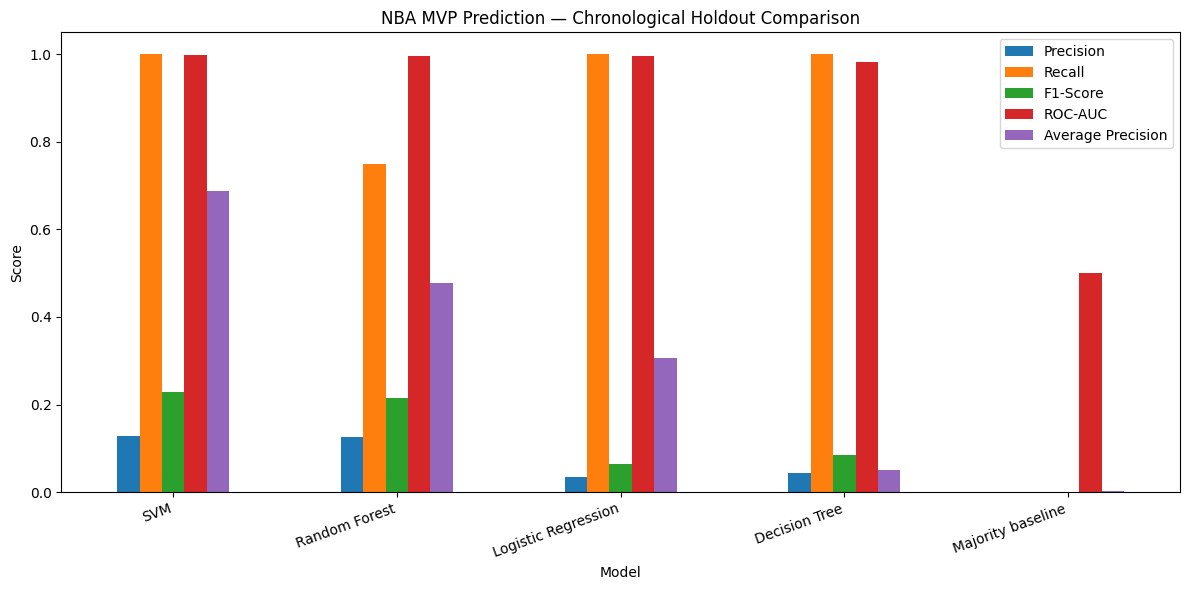

In [5]:
# 4. Evaluate models on the held-out future seasons.
# Scores are based on this particular chronological split; only four test seasons
# are available, so treat the estimates as preliminary.

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

evaluation_rows = []
test_predictions = {}

for name, model in fitted_models.items():
    y_pred = model.predict(X_test)
    y_score = model.predict_proba(X_test)[:, 1]
    test_predictions[name] = {"predicted": y_pred, "score": y_score}

    evaluation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "Average Precision": average_precision_score(y_test, y_score)
    })

results_df = pd.DataFrame(evaluation_rows).sort_values(
    "Average Precision", ascending=False
)
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Confusion matrices for the four requested classifiers.
for name in ["Logistic Regression", "Decision Tree", "Random Forest", "SVM"]:
    print(f"\n{name} confusion matrix (rows=actual, columns=predicted):")
    print(confusion_matrix(y_test, test_predictions[name]["predicted"]))

ax = results_df.set_index("Model")[
    ["Precision", "Recall", "F1-Score", "ROC-AUC", "Average Precision"]
].plot(kind="bar", figsize=(12, 6))
ax.set_title("NBA MVP Prediction — Chronological Holdout Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [6]:
# 5. Generate predictions while preserving metadata from test_data.
# Ranking is done separately for each season; no index-based name lookup is used.

prediction_data = test_data[metadata_cols + features + [target]].copy()

probability_columns = {
    "Logistic Regression": "Logistic_Probability",
    "Decision Tree": "DecisionTree_Probability",
    "Random Forest": "RandomForest_Probability",
    "SVM": "SVM_Probability"
}
for model_name, output_col in probability_columns.items():
    prediction_data[output_col] = fitted_models[model_name].predict_proba(X_test)[:, 1]

probability_cols = list(probability_columns.values())
prediction_data["Combined_MVP_Score"] = prediction_data[probability_cols].mean(axis=1)
prediction_data["Season_Rank"] = (
    prediction_data.groupby("season")["Combined_MVP_Score"]
    .rank(method="min", ascending=False)
    .astype(int)
)

final_ranking = prediction_data.sort_values(
    ["season", "Season_Rank", "player"]
).reset_index(drop=True)

for season in sorted(final_ranking["season"].unique()):
    print(f"\n========== TOP 5 CANDIDATES — {int(season)} ==========")
    print(
        final_ranking.loc[final_ranking["season"].eq(season)].head(5)[
            ["season", "player", "player_id", "Combined_MVP_Score", "Season_Rank", "MVP"]
        ].to_string(index=False)
    )

# Evaluate whether the actual MVP appears at rank 1 or in the top 5 for each test season.
season_rows = []
for season, season_df in final_ranking.groupby("season"):
    season_df = season_df.sort_values("Combined_MVP_Score", ascending=False)
    actual_winners = season_df[season_df["MVP"].eq(1)]
    if actual_winners.empty:
        continue
    winner_ids = set(actual_winners["player_id"])
    top1_ids = set(season_df.head(1)["player_id"])
    top5_ids = set(season_df.head(5)["player_id"])
    season_rows.append({
        "Season": int(season),
        "Actual MVP": ", ".join(actual_winners["player"].astype(str)),
        "Top-1 correct": int(bool(winner_ids & top1_ids)),
        "MVP in top 5": int(bool(winner_ids & top5_ids))
    })

season_ranking_metrics = pd.DataFrame(season_rows)
print("\nSeason-wise ranking evaluation:")
print(season_ranking_metrics.to_string(index=False))
if not season_ranking_metrics.empty:
    print("\nTop-1 accuracy across evaluated seasons:",
          f"{season_ranking_metrics['Top-1 correct'].mean():.3f}")
    print("Top-5 inclusion across evaluated seasons:",
          f"{season_ranking_metrics['MVP in top 5'].mean():.3f}")


========== TOP 5 CANDIDATES — 2022 ==========
 season                player player_id  Combined_MVP_Score  Season_Rank  MVP
   2022          Nikola Jokić jokicni01            0.882625            1    1
   2022 Giannis Antetokounmpo antetgi01            0.749838            2    0
   2022           Joel Embiid embiijo01            0.657586            3    0
   2022          LeBron James jamesle01            0.624725            4    0
   2022          Jayson Tatum tatumja01            0.621098            5    0

========== TOP 5 CANDIDATES — 2023 ==========
 season                player player_id  Combined_MVP_Score  Season_Rank  MVP
   2023          Nikola Jokić jokicni01            0.808548            1    0
   2023           Joel Embiid embiijo01            0.681390            2    1
   2023           Luka Dončić doncilu01            0.681358            3    0
   2023          Jayson Tatum tatumja01            0.675827            4    0
   2023 Giannis Antetokounmpo antetgi01         


Random Forest — top features
     Feature  Importance
pts_per_game    0.258655
 mp_per_game    0.213330
trb_per_game    0.153016
ast_per_game    0.136033
tov_per_game    0.057934
          gs    0.037284
           g    0.037249
  fg_percent    0.031142
stl_per_game    0.021757
  ft_percent    0.018403

Decision Tree — top features
     Feature   Importance
pts_per_game 7.756728e-01
trb_per_game 1.104820e-01
ast_per_game 9.533236e-02
  ft_percent 1.169992e-02
           g 2.443257e-03
         age 2.275379e-03
 x3p_percent 2.094300e-03
tov_per_game 1.643782e-19
          gs 0.000000e+00
  fg_percent 0.000000e+00

Logistic Regression — top features
     Feature  Importance
pts_per_game    3.072469
trb_per_game    2.255062
ast_per_game    1.890869
 mp_per_game    1.750705
           g    0.871581
  fg_percent    0.819668
  ft_percent    0.788256
         age    0.551116
tov_per_game    0.171513
          gs    0.095243

SVM permutation — top features
     Feature  Importance
pts_per_gam

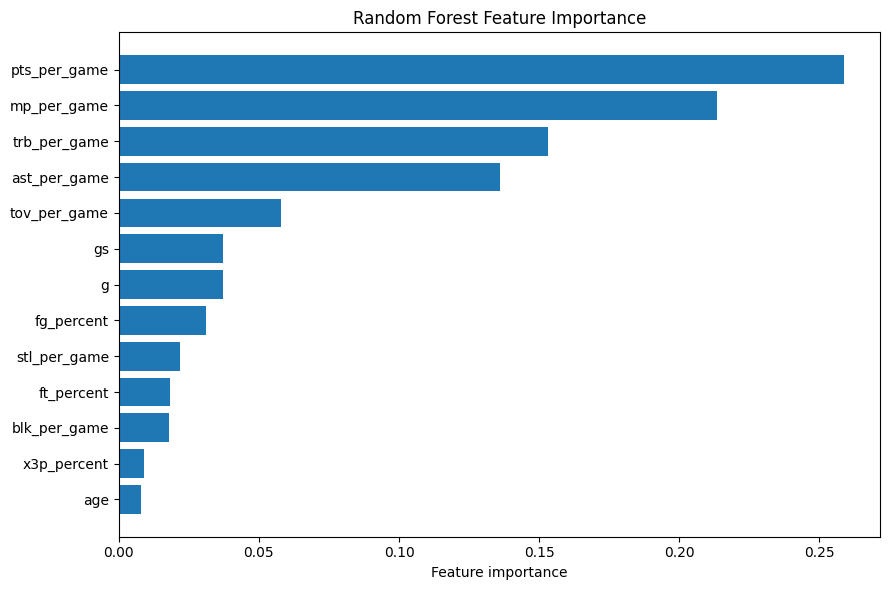

In [7]:
# 6. Feature importance / interpretation.
# For the SVM, permutation importance is computed on raw X_test because the
# full pipeline applies the same imputation/scaling steps internally.

from sklearn.inspection import permutation_importance

OUT_DIR = Path("/content/outputs") if Path("/content").exists() else Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

rf_estimator = fitted_models["Random Forest"].named_steps["model"]
dt_estimator = fitted_models["Decision Tree"].named_steps["model"]
lr_estimator = fitted_models["Logistic Regression"].named_steps["model"]

rf_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_estimator.feature_importances_
}).sort_values("Importance", ascending=False)

dt_df = pd.DataFrame({
    "Feature": features,
    "Importance": dt_estimator.feature_importances_
}).sort_values("Importance", ascending=False)

# Logistic regression coefficients are from standardized features.
lr_df = pd.DataFrame({
    "Feature": features,
    "Importance": np.abs(lr_estimator.coef_[0])
}).sort_values("Importance", ascending=False)

svm_perm = permutation_importance(
    fitted_models["SVM"], X_test, y_test,
    n_repeats=5, random_state=SEED, scoring="average_precision"
)
svm_df = pd.DataFrame({
    "Feature": features,
    "Importance": svm_perm.importances_mean
}).sort_values("Importance", ascending=False)

for name, frame in [
    ("Random Forest", rf_df),
    ("Decision Tree", dt_df),
    ("Logistic Regression", lr_df),
    ("SVM permutation", svm_df)
]:
    print(f"\n{name} — top features")
    print(frame.head(10).to_string(index=False))

rf_df.to_csv(OUT_DIR / "random_forest_feature_importance.csv", index=False)
dt_df.to_csv(OUT_DIR / "decision_tree_feature_importance.csv", index=False)
lr_df.to_csv(OUT_DIR / "logistic_regression_feature_importance.csv", index=False)
svm_df.to_csv(OUT_DIR / "svm_feature_importance.csv", index=False)

rf_plot = rf_df.sort_values("Importance", ascending=True)
plt.figure(figsize=(9, 6))
plt.barh(rf_plot["Feature"], rf_plot["Importance"])
plt.xlabel("Feature importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

In [8]:
# 7. Save reproducible outputs and run final sanity checks.

results_df.to_csv(OUT_DIR / "model_evaluation.csv", index=False)
season_ranking_metrics.to_csv(OUT_DIR / "season_ranking_evaluation.csv", index=False)
final_ranking.to_csv(OUT_DIR / "final_mvp_ranking.csv", index=False)

# Keep metadata in the exported dataset so labels can be audited.
model_data.to_csv(OUT_DIR / "nba_mvp_model_data.csv", index=False)

print("Output folder:", OUT_DIR.name + "/")
print("\nFiles saved:")
for path in sorted(OUT_DIR.glob("*.csv")):
    print(f"- {path.name} ({path.stat().st_size:,} bytes)")

print("\nSanity checks:")
print("Duplicate player-season keys in model data:",
      int(model_data.duplicated(subset=["season", "player_id"]).sum()))
print("Positive MVP labels in model data:", int(model_data["MVP"].sum()))
print("Positive MVP labels retained in training data:", int(y_train.sum()))
print("Positive MVP labels in test data:", int(y_test.sum()))
print("Player names missing in prediction data:", int(prediction_data["player"].isna().sum()))
print("Seasons in final ranking:", sorted(final_ranking["season"].unique().tolist()))

# Every positive label should correspond to a winner from the MVP award table.
winner_keys = set(zip(mvp_winners["season"], mvp_winners["player_id"]))
positive_keys = set(zip(
    model_data.loc[model_data["MVP"].eq(1), "season"],
    model_data.loc[model_data["MVP"].eq(1), "player_id"]
))
unmatched_positive = positive_keys - winner_keys
print("Positive labels not found in the MVP winner table:", len(unmatched_positive))
if unmatched_positive:
    print(sorted(unmatched_positive)[:10])

Output folder: outputs/

Files saved:
- decision_tree_feature_importance.csv (336 bytes)
- final_mvp_ranking.csv (388,859 bytes)
- logistic_regression_feature_importance.csv (402 bytes)
- model_evaluation.csv (571 bytes)
- nba_mvp_model_data.csv (2,155,623 bytes)
- random_forest_feature_importance.csv (418 bytes)
- season_ranking_evaluation.csv (145 bytes)
- svm_feature_importance.csv (406 bytes)

Sanity checks:
Duplicate player-season keys in model data: 0
Positive MVP labels in model data: 70
Positive MVP labels retained in training data: 66
Positive MVP labels in test data: 4
Player names missing in prediction data: 0
Seasons in final ranking: [2022, 2023, 2024, 2025]
Positive labels not found in the MVP winner table: 0
